### Importing Relevant Libraries

In [45]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

pd.set_option("display.max_columns", None)

## K-Means Prctical Project

### Loading the dataset

In [46]:
# Loading dataset

country_df = pd.read_csv("../data/Country-data.csv")

country_df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


### Basic Checks

In [47]:
# Checking data quality

def basic_checks(df):
    print("-"*35, "Missing Values", "-"*35)
    print(df.isnull().sum())

    print("-"*35, "Duplicates", "-"*35)
    print(df.duplicated().sum())

    print("-"*35, "Statistical Analysis", "-"*35)
    print(display(df.describe().T))

    print("-"*35, "Data Types", "-"*35)
    print(df.dtypes)

    print("-"*35, "Data shape", "-"*35)
    print(df.shape)

    print("-"*35, "Data Information", "-"*35)
    print(df.info())

    print("-"*35, "Columns", "-"*35)
    print(df.columns.unique())


basic_checks(country_df)

----------------------------------- Missing Values -----------------------------------
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64
----------------------------------- Duplicates -----------------------------------
0
----------------------------------- Statistical Analysis -----------------------------------


,count,mean,std,min,25%,50%,75%,max
child_mort,167.0,38.270060,40.328931,2.6000,8.250,19.30,62.10,208.00
exports,167.0,41.108976,27.412010,0.1090,23.800,35.00,51.35,200.00
health,167.0,6.815689,2.746837,1.8100,4.920,6.32,8.60,17.90
imports,167.0,46.890215,24.209589,0.0659,30.200,43.30,58.75,174.00
income,167.0,17144.688623,19278.067698,609.0000,3355.000,9960.00,22800.00,125000.00
inflation,167.0,7.781832,10.570704,-4.2100,1.810,5.39,10.75,104.00
life_expec,167.0,70.555689,8.893172,32.1000,65.300,73.10,76.80,82.80
total_fer,167.0,2.947964,1.513848,1.1500,1.795,2.41,3.88,7.49
gdpp,167.0,12964.155689,18328.704809,231.0000,1330.000,4660.00,14050.00,105000.00


None
----------------------------------- Data Types -----------------------------------
country           str
child_mort    float64
exports       float64
health        float64
imports       float64
income          int64
inflation     float64
life_expec    float64
total_fer     float64
gdpp            int64
dtype: object
----------------------------------- Data shape -----------------------------------
(167, 10)
----------------------------------- Data Information -----------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    

### Exploratory Data Analysis

- Numerical columns distribution

In [48]:
features = country_df.drop(columns=["country"])

feature_names = features.columns.to_list()

feature_names

['child_mort',
 'exports',
 'health',
 'imports',
 'income',
 'inflation',
 'life_expec',
 'total_fer',
 'gdpp']

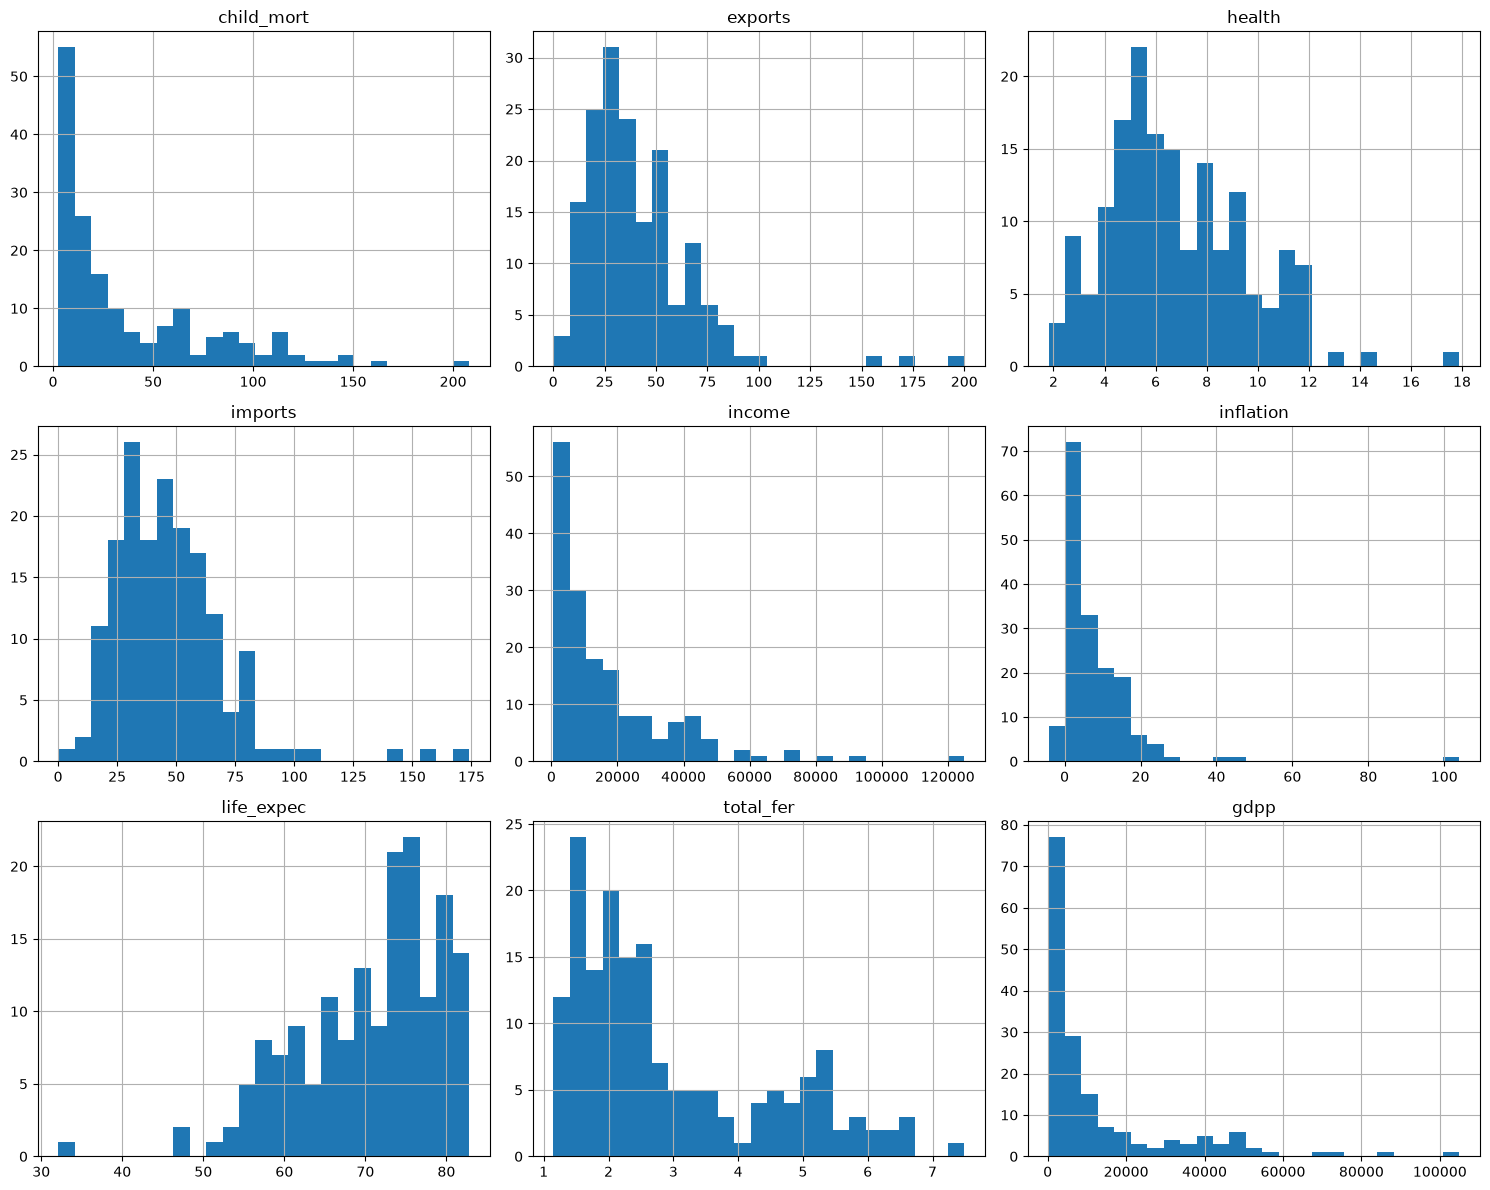

In [49]:
features.hist(figsize=(15, 12), bins=25)
plt.tight_layout()
plt.show()

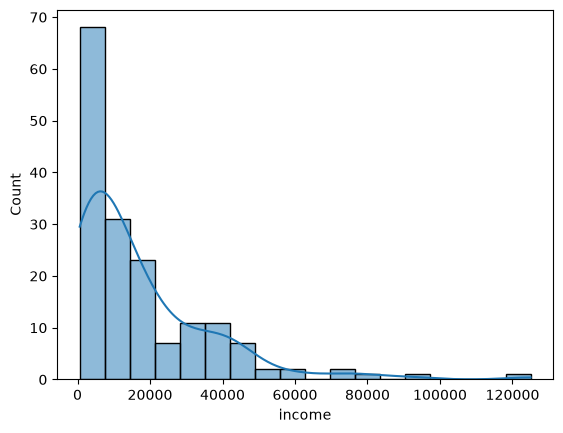

In [50]:
sns.histplot(features['income'], kde=True)
plt.show()

- Checking Outliers

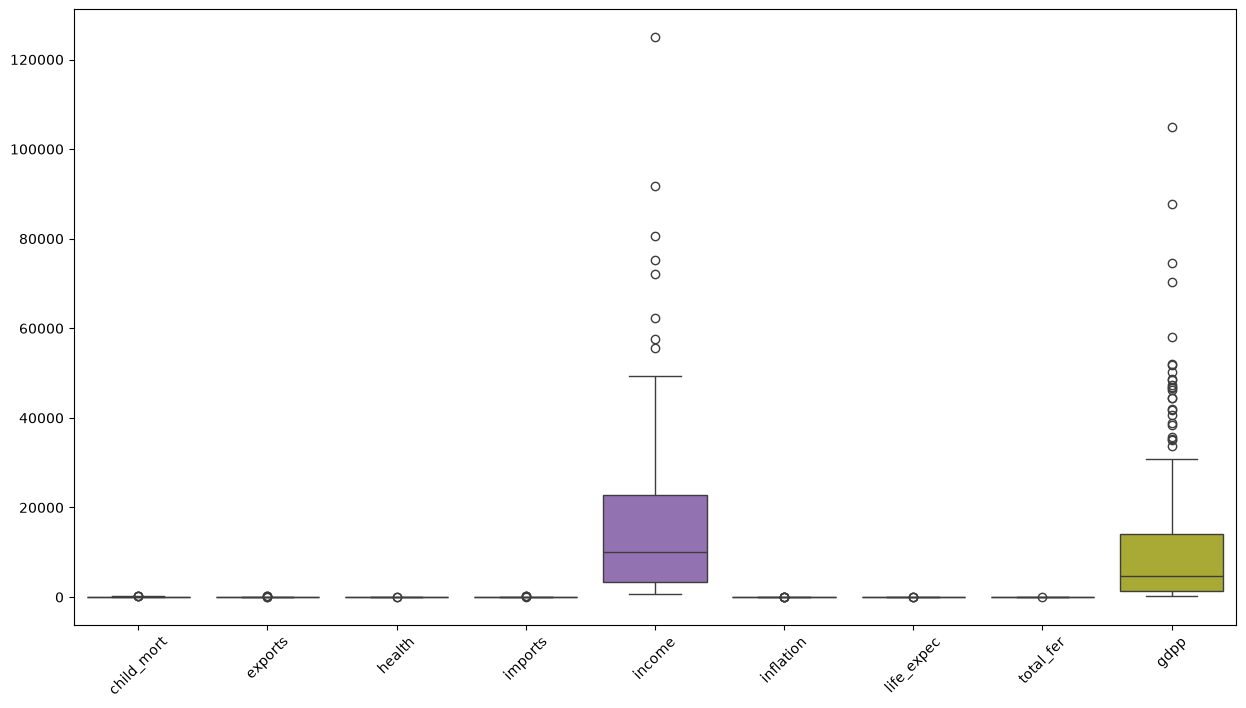

In [51]:
plt.figure(figsize=(15, 8))

sns.boxplot(data=features[
    ['child_mort', 'exports', 'health', 'imports',
     'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']
])

plt.xticks(rotation=45)
plt.show()

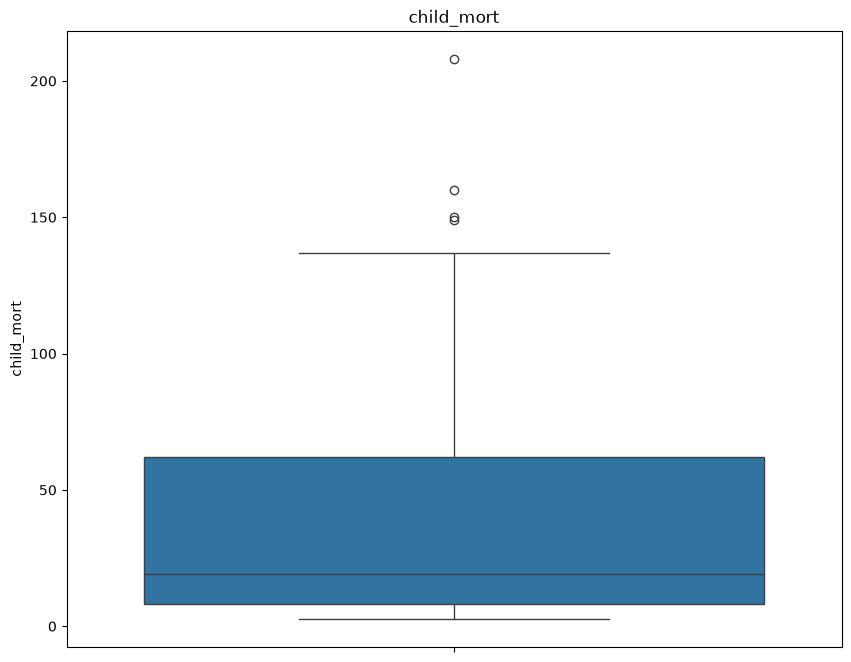

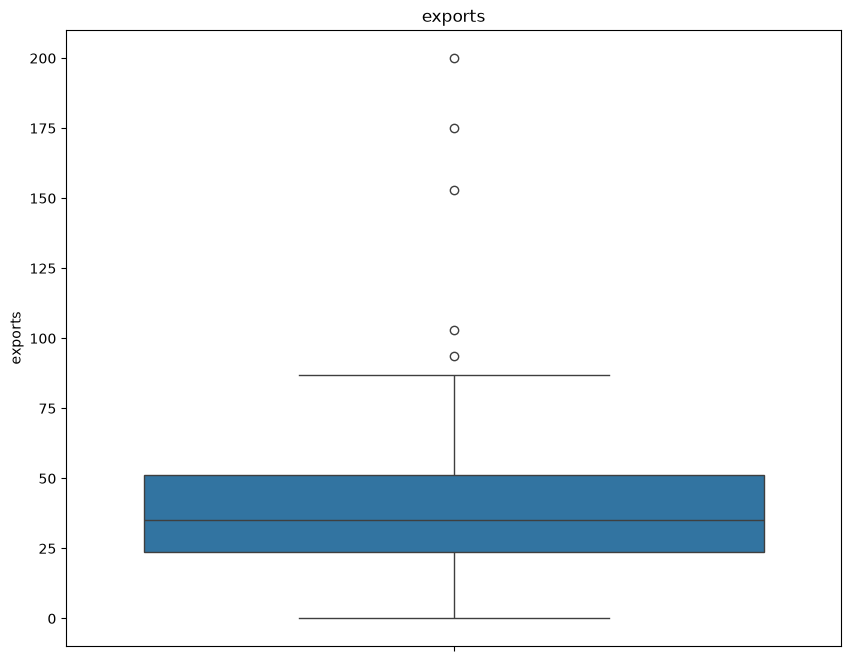

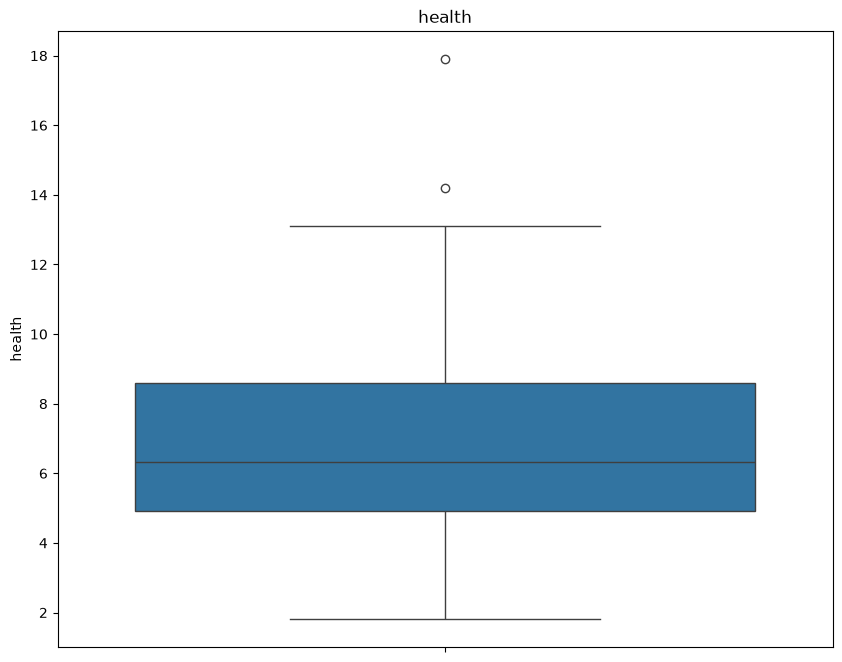

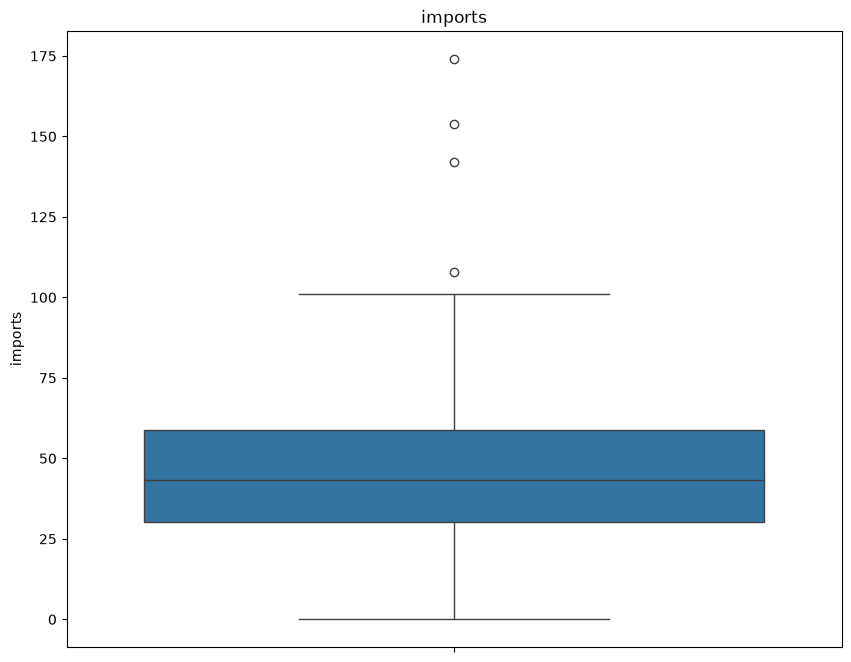

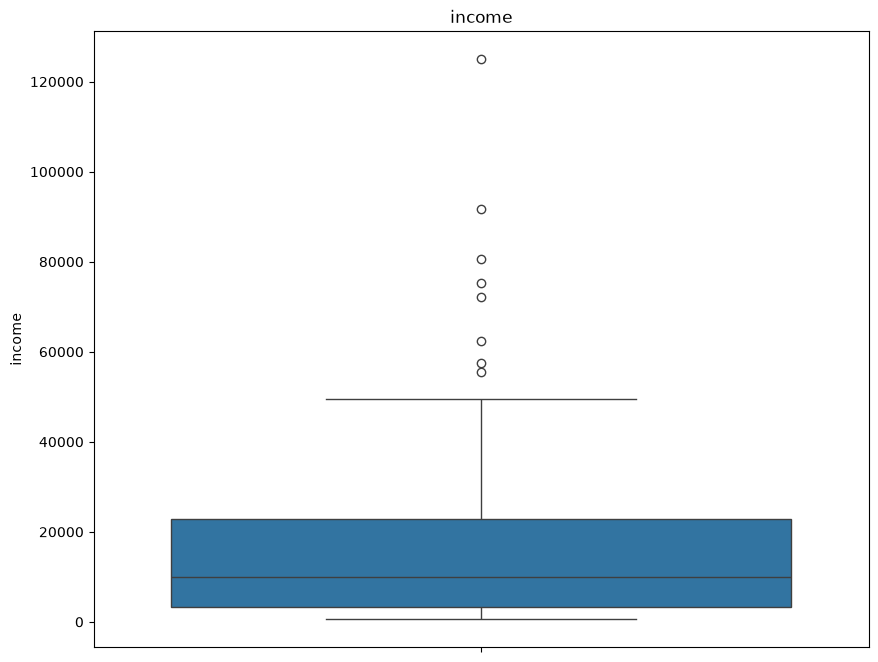

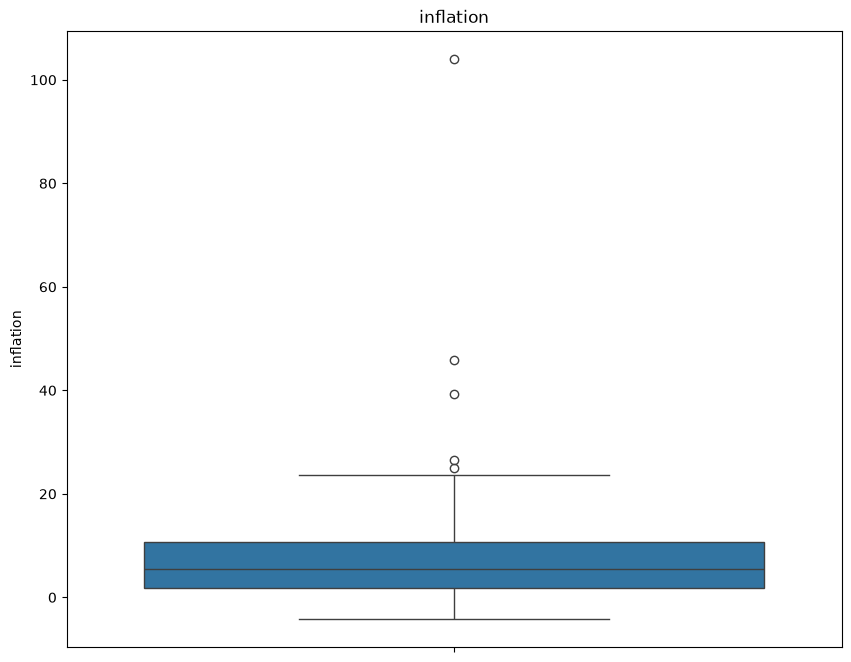

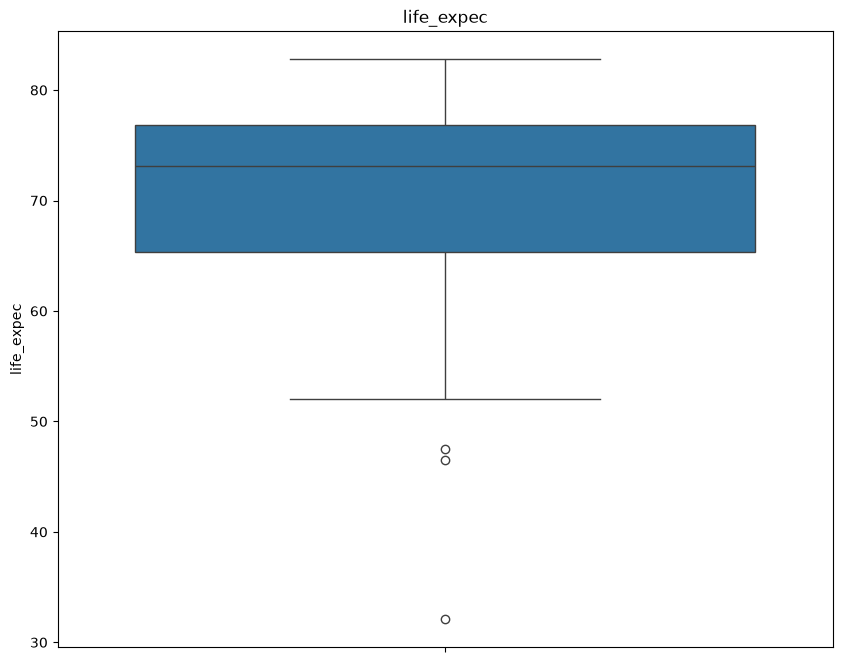

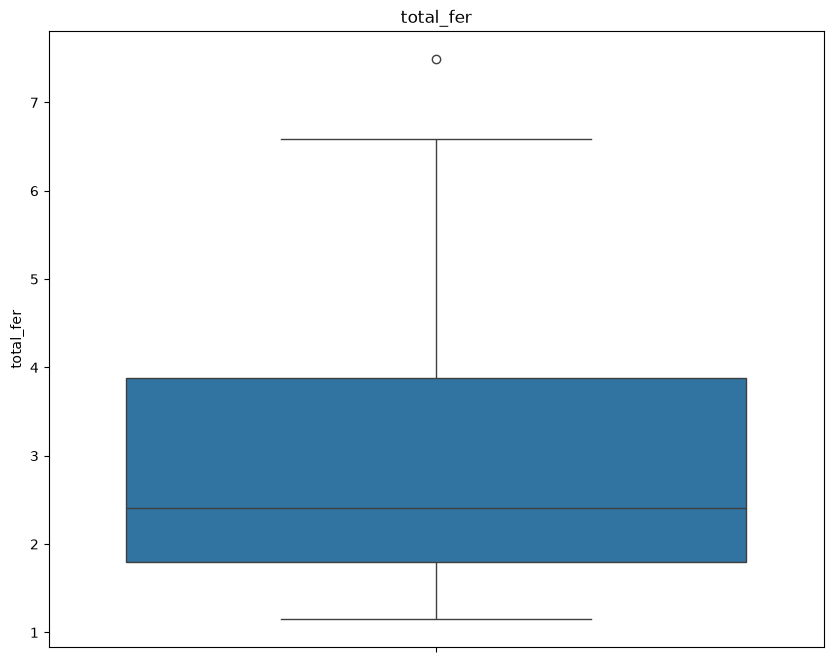

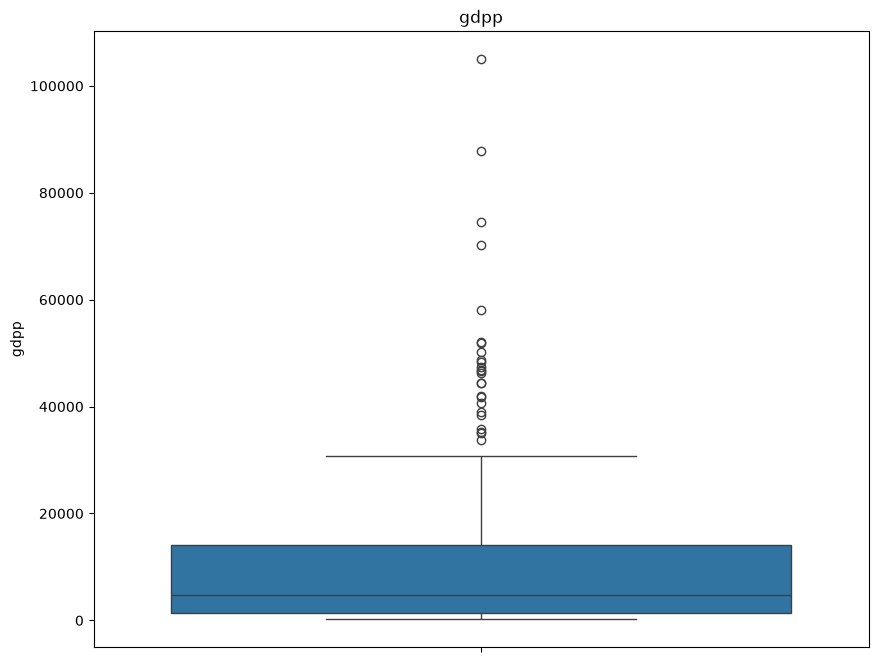

In [52]:
# Checking Outliers for Every Numerical Columns Individually

for col in feature_names:
    plt.figure(figsize=(10, 8))
    sns.boxplot(features, y=col)
    plt.title(col)
    plt.show()

In [53]:
features.select_dtypes(include='number').skew().sort_values(ascending=False)

inflation     5.154049
exports       2.445824
income        2.231480
gdpp          2.218051
imports       1.905276
child_mort    1.450774
total_fer     0.967092
health        0.705746
life_expec   -0.970996
dtype: float64

### Correlation Analysis

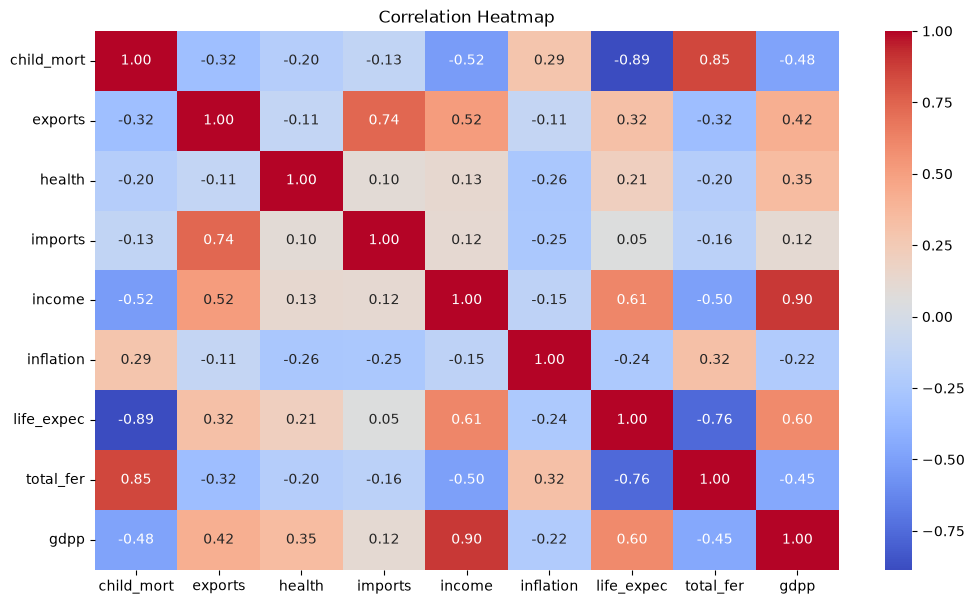

In [54]:
corr = features.select_dtypes(include='number').corr()

plt.figure(figsize=(12, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

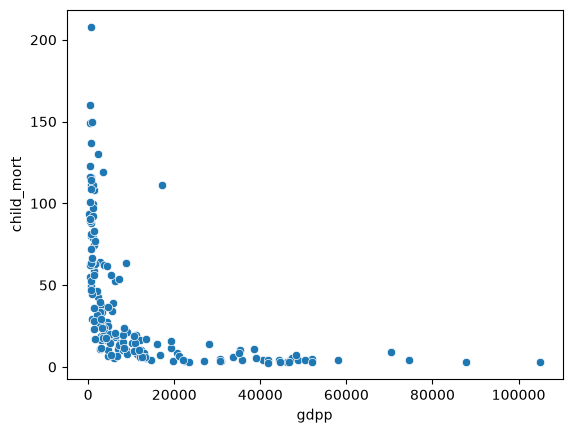

In [55]:
sns.scatterplot(features, x='gdpp', y='child_mort')
plt.show()

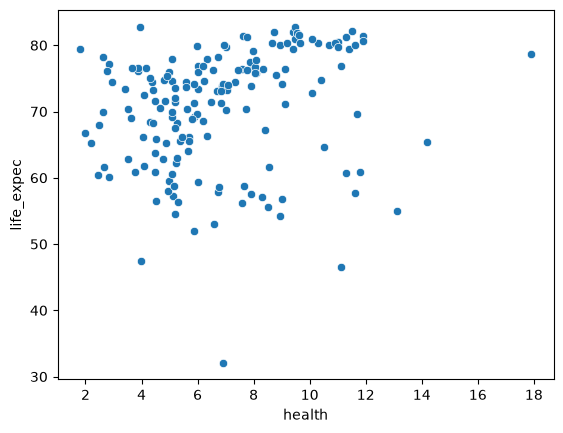

In [56]:
sns.scatterplot(features, x='health', y='life_expec')
plt.show()

### Preprocessing

- Scaling

In [57]:
# Instantiate scaler

scaler = StandardScaler()

country_df_scaled = scaler.fit_transform(features) 

In [58]:
X = pd.DataFrame(country_df_scaled, index=features.index)

X.head()

,0,1,2,3,4,5,6,7,8
0,1.291532,-1.138280,0.279088,-0.082455,-0.808245,0.157336,-1.619092,1.902882,-0.679180
1,-0.538949,-0.479658,-0.097016,0.070837,-0.375369,-0.312347,0.647866,-0.859973,-0.485623
2,-0.272833,-0.099122,-0.966073,-0.641762,-0.220844,0.789274,0.670423,-0.038404,-0.465376
3,2.007808,0.775381,-1.448071,-0.165315,-0.585043,1.387054,-1.179234,2.128151,-0.516268
4,-0.695634,0.160668,-0.286894,0.497568,0.101732,-0.601749,0.704258,-0.541946,-0.041817


### K Means Clustering

#### Choosing K
- Method 1: Elbow Method

In [59]:
# Elbow Method

k_range = range(1, 11)

inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)

    km.fit(X)
    inertias.append(km.inertia_)

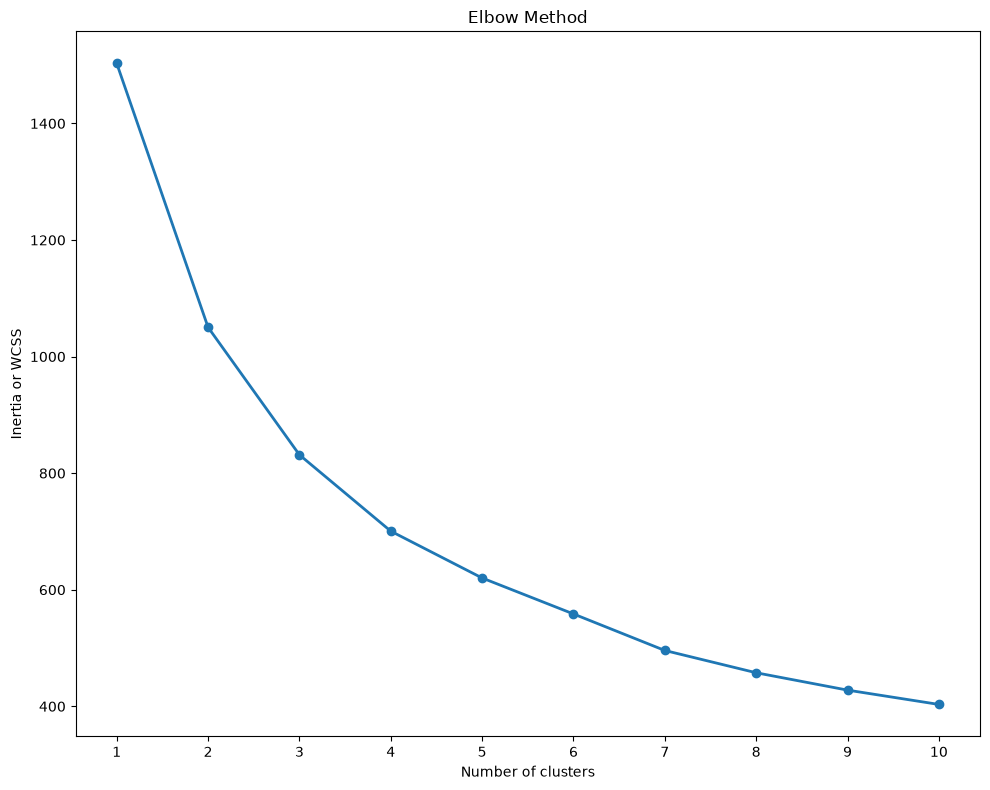

In [60]:
plt.figure(figsize=(10, 8))
plt.plot(list(k_range), inertias, marker="o", linewidth=2)
plt.xlabel("Number of clusters")
plt.ylabel("Inertia or WCSS")
plt.title("Elbow Method")
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

#### Silhouette Score

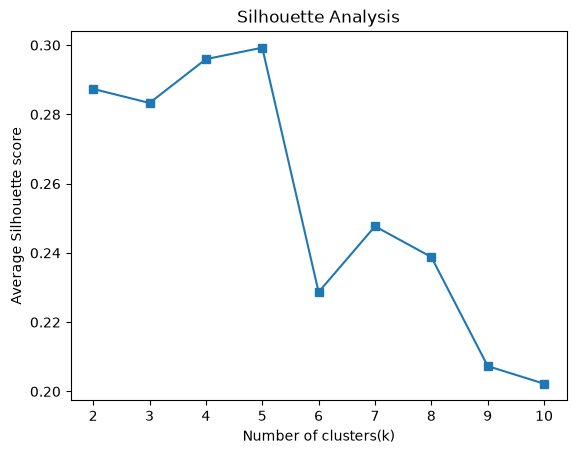

In [61]:
sil_range = range(2, 11)

sil_score = []

for k in sil_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)

    labels = km.fit_predict(X)
    sil_score.append(silhouette_score(X, labels))

plt.Figure(figsize=(10, 8))
plt.plot(list(sil_range), sil_score, marker="s")
plt.title("Silhouette Analysis")
plt.xlabel("Number of clusters(k)")
plt.ylabel("Average Silhouette score")
plt.xticks(list(sil_range))
plt.show()

#### Fitting the final K-Means model

In [62]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(X)

#### Attach the cluster number to the original dataframe

In [63]:
country_df["kmeans_cluster"] = kmeans_labels

country_df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,kmeans_cluster
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,1
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,2
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,2
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,1
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,2


## Hierarchical Clustering

- Visualizing Dendogram

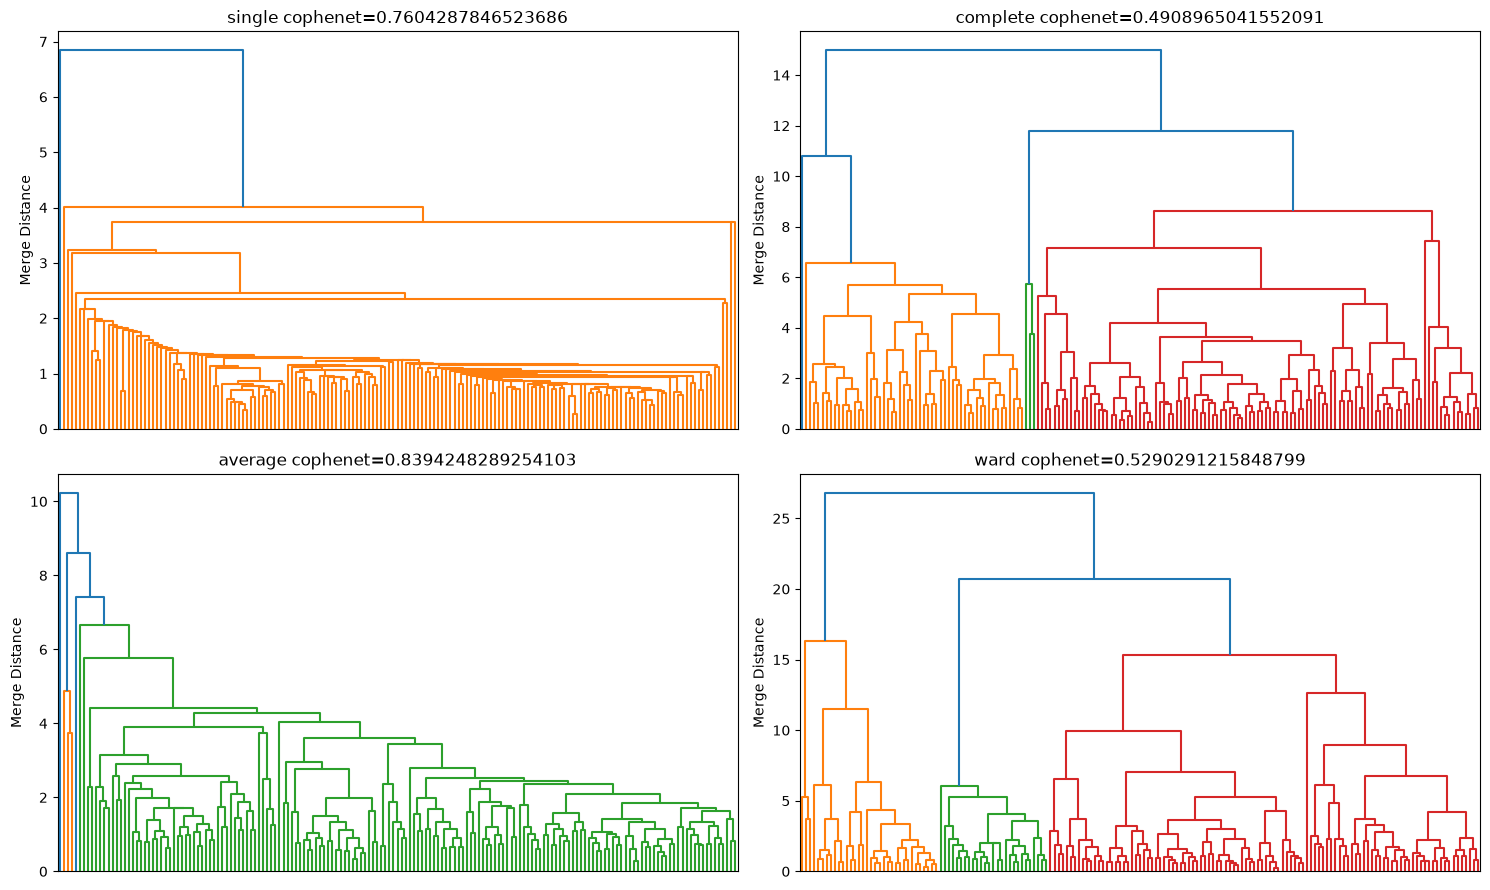

In [64]:
# Compare Four Methods Linkage For the same data

methods = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for ax, method in zip(axes.flatten(), methods):
    Z_m = linkage(X, method = method)
    dendrogram(Z_m, ax = ax, no_labels=True)
    c, _ = cophenet(Z_m, pdist(X))
    ax.set_title(f"{method} cophenet={c}")
    ax.set_ylabel("Merge Distance")

plt.tight_layout()
plt.show()


In [66]:
country_df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,kmeans_cluster
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,1
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,2
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,2
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,1
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,2


#### Building a Dendrogram Using the Average Linkage 

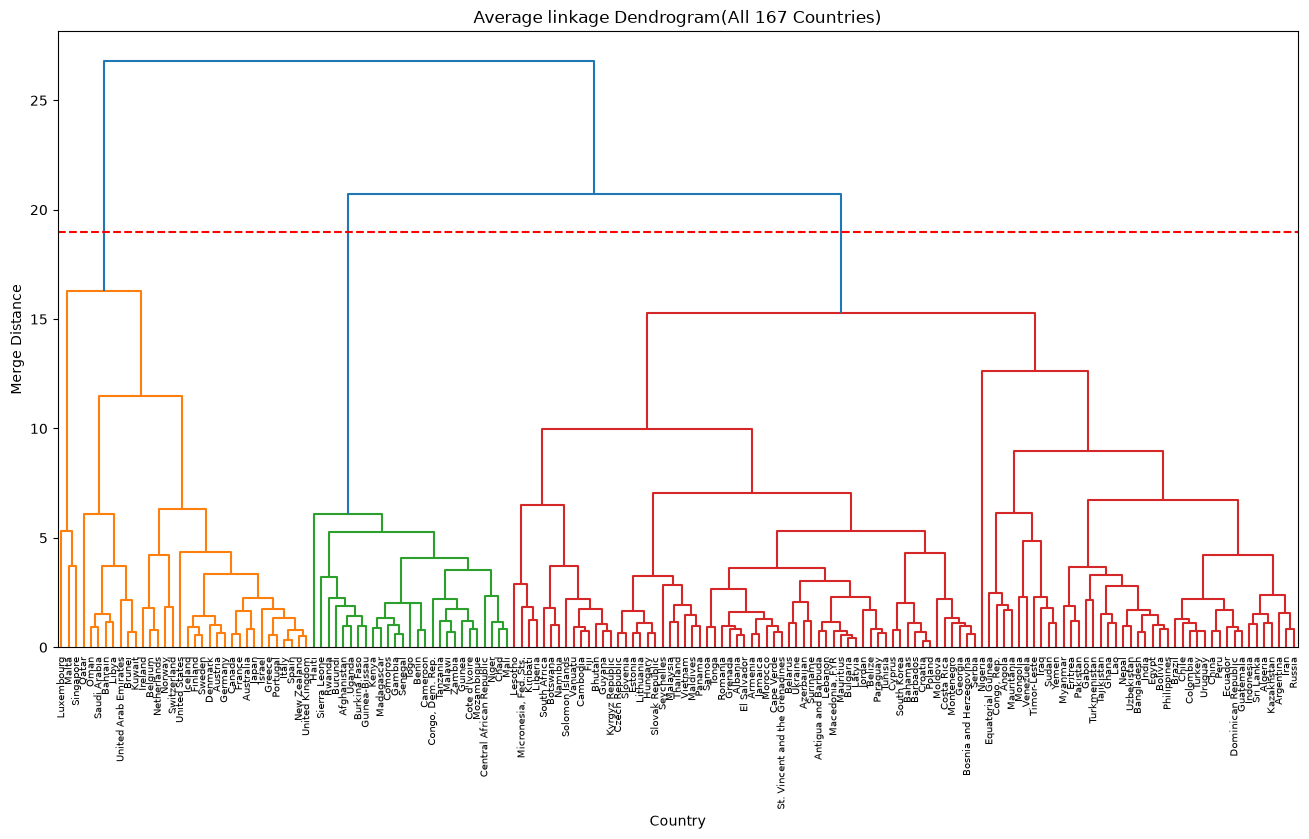

In [70]:
Z = linkage(X, method = "ward")

plt.figure(figsize=(16, 8))
dendrogram(Z, labels=country_df["country"].values, leaf_rotation=90, leaf_font_size=7)
plt.axhline(y=19, color="red", ls="--", label="cut here 3 clusters")
plt.title("Average linkage Dendrogram(All 167 Countries)")
plt.xlabel("Country")
plt.ylabel("Merge Distance")
plt.show()